In [13]:
# necessary imports 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import logging
import sys

# plotting imports
import pandapower as pp
import pandapower.topology as top
import pandapower.plotting as plot
import simbench as sb

# simbench imports
import simbench as sb

# DWD imports (German weather data), open source
import urllib.request
import zipfile, io

In [3]:
# we know already from the paper that the project SimBench was active between 2015 and 2019; 
# in order to obtain actual temp. data, we now need to confirm what year the data corresponds to

In [4]:
# find out from what years the simbench data originates 
path_lp = '/opt/anaconda3/envs/p2p/lib/python3.10/site-packages/simbench/networks/1-complete_data-mixed-all-0-sw/LoadProfile.csv'
lp_raw = pd.read_csv(path_lp, sep=';', nrows=5)
print("First rows of time column:")
print(lp_raw.iloc[:5, 0])  # first column is time

# Also check the full index range
lp_full = pd.read_csv(path_lp, sep=';', index_col=0)
print(f"\nIndex type: {type(lp_full.index)}")
print(f"First value: {lp_full.index[0]}")
print(f"Last value:  {lp_full.index[-1]}")
print(f"Total rows:  {len(lp_full)}")
print(f"35136 / 4 / 24 = {35136/4/24:.0f} days = 1 year")

First rows of time column:
0    01.01.2016 00:00
1    01.01.2016 00:15
2    01.01.2016 00:30
3    01.01.2016 00:45
4    01.01.2016 01:00
Name: time, dtype: object

Index type: <class 'pandas.core.indexes.base.Index'>
First value: 01.01.2016 00:00
Last value:  31.12.2016 23:45
Total rows:  35136
35136 / 4 / 24 = 366 days = 1 year


In [5]:
# this shows that the data we have available in Simbench is form the year 2016; it corresponds exactly to one year

DWD DATA OVERVIEW: 

/hourly/air_temperature/     → temperature 
/hourly/solar/               → global radiation, diffuse radiation, sunshine hours
/hourly/cloudiness/          → cloud cover in oktas (0–8)
/hourly/precipitation/       → mm per hour
/hourly/moisture/            → humidity, dew point
/hourly/wind/                → wind speed and direction

--> extract temp. data to calculate line thermal limits/temperature constraints of devices

** TEMPERATURE DATA DWD YEAR 2016 - HANNOVER, LÜBECK **

In [ ]:
# Step 1 - Data Import 
def dwd_hourly_temp(station_id, year):
    import urllib.request, zipfile, io, re
    base = "https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/hourly/air_temperature/historical/"
    
    with urllib.request.urlopen(base) as r:
        html = r.read().decode()
    
    fname = re.findall(rf'stundenwerte_TU_{station_id:05d}_\d+_\d+_hist\.zip', html)
    if not fname:
        raise ValueError(f"Station {station_id} not found in DWD index")
    
    url = base + fname[0]
    print(f"Downloading: {fname[0]}")
    
    with urllib.request.urlopen(url) as r:
        z = zipfile.ZipFile(io.BytesIO(r.read()))
        data_file = [f for f in z.namelist() if f.startswith('produkt_')][0]
        df = pd.read_csv(z.open(data_file), sep=';')
    
    # DWD stores datetime as integer YYYYMMDDHH — parse explicitly
    df['datetime'] = pd.to_datetime(df['MESS_DATUM'].astype(str).str.strip(),
                                    format='%Y%m%d%H')
    df['temp_C'] = pd.to_numeric(df['TT_TU'].astype(str).str.strip(),
                                  errors='coerce')
    
    df = df[df['datetime'].dt.year == year][['datetime','temp_C']]
    df = df.dropna().reset_index(drop=True)
    
    print(f"  Got {len(df)} hourly records for {year}")
    print(f"  Range: {df['datetime'].iloc[0]} → {df['datetime'].iloc[-1]}")
    print(f"  Temp: {df['temp_C'].min():.1f}°C to {df['temp_C'].max():.1f}°C")
    
    return df

temp_hannover = dwd_hourly_temp(2564, 2016)
temp_luebeck  = dwd_hourly_temp(2928, 2016)

Downloading: stundenwerte_TU_02564_20020101_20251231_hist.zip
  Got 8784 hourly records for 2016
  Range: 2016-01-01 00:00:00 → 2016-12-31 23:00:00
  Temp: -8.3°C to 30.2°C
Downloading: stundenwerte_TU_02928_19510101_20251231_hist.zip
  Got 8784 hourly records for 2016
  Range: 2016-01-01 00:00:00 → 2016-12-31 23:00:00
  Temp: -11.2°C to 34.9°C


In [7]:
# Step 2 — Upsample to 15-min to match SimBench
def to_15min(df):
    df = df.set_index('datetime')
    df.index = pd.to_datetime(df.index)
    return df.resample('15min').interpolate('linear')

temp_han_15 = to_15min(temp_hannover)
temp_lub_15 = to_15min(temp_luebeck)
print(f"After upsampling: {len(temp_han_15)} steps (expect 35136)")

After upsampling: 35133 steps (expect 35136)


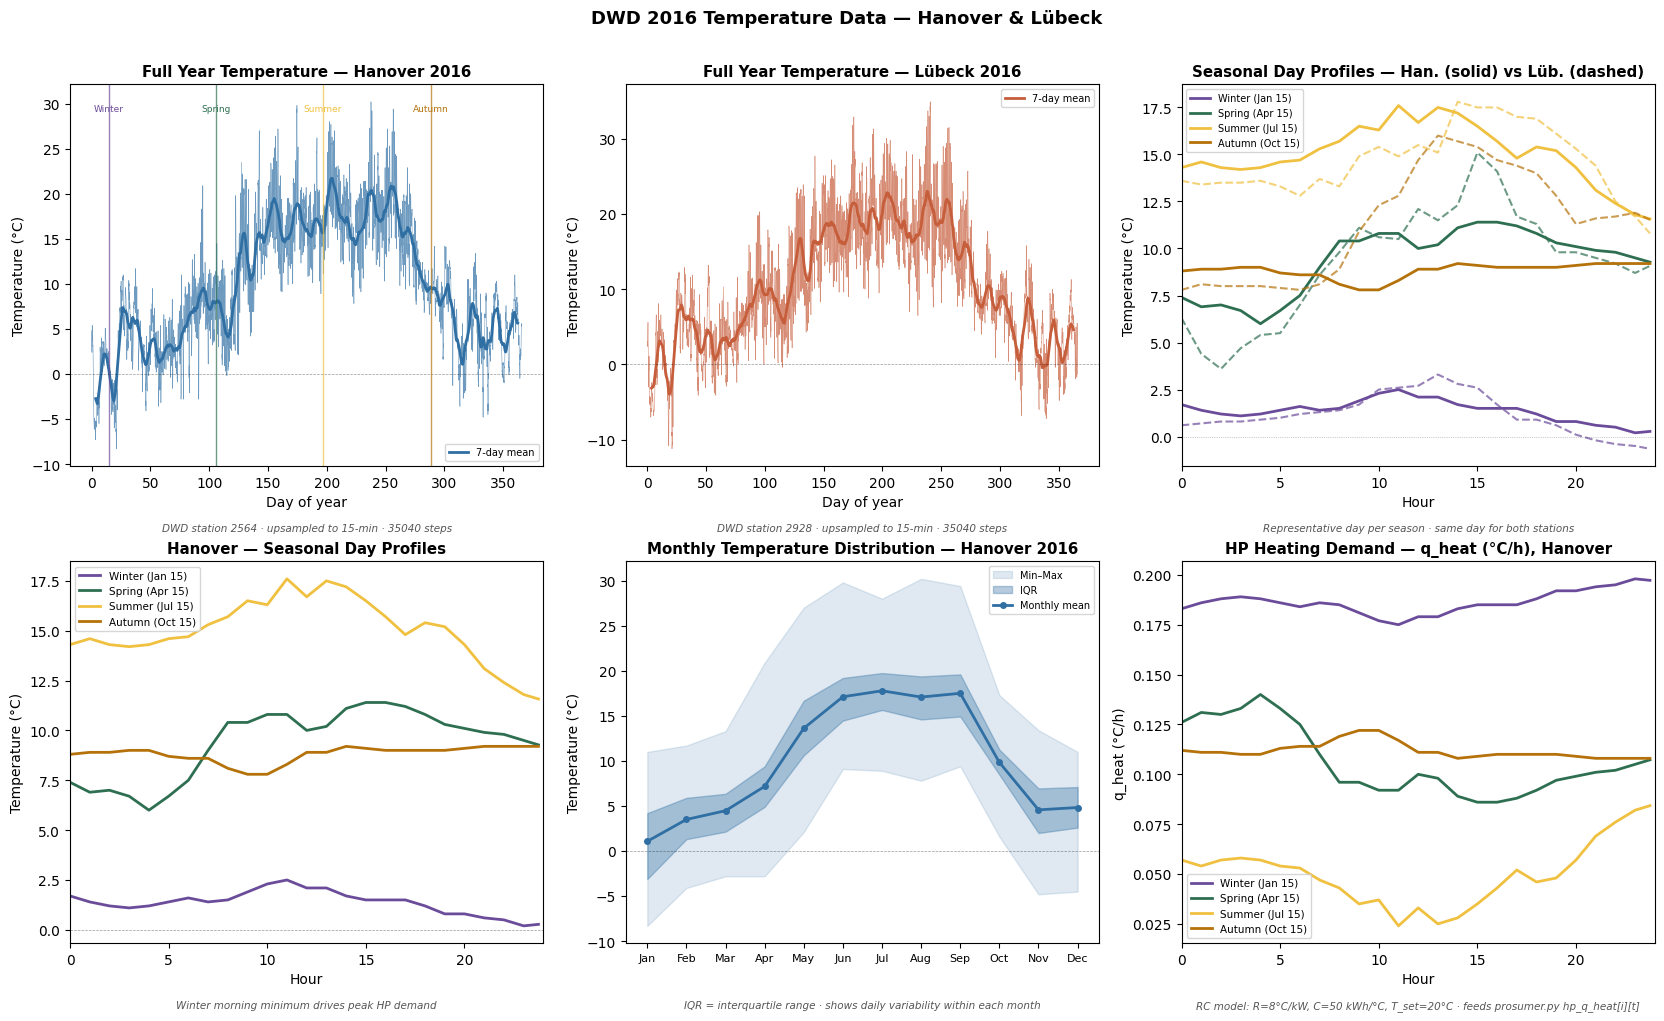

In [ ]:
# Step 3 - Visualisation 

# Build seasonal day slices (15-min resolution, 2016)
seasons = {
    'Winter (Jan 15)': slice(14*96, 15*96),
    'Spring (Apr 15)': slice((31+29+31+14)*96, (31+29+31+15)*96),
    'Summer (Jul 15)': slice((31+29+31+30+31+30+14)*96, (31+29+31+30+31+30+15)*96),
    'Autumn (Oct 15)': slice((31+29+31+30+31+30+31+31+30+14)*96,
                              (31+29+31+30+31+30+31+31+30+15)*96),
}
t_day = np.arange(96) * 0.25   # hours 0–24

han = temp_han_15['temp_C'].values
lub = temp_lub_15['temp_C'].values

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
plt.rcParams.update({'font.size':9,'axes.spines.top':False,
                     'axes.spines.right':False,'pdf.fonttype':42})

COLORS = {'Hanover':'#2F6FA3', 'Lübeck':'#C65D3B'}
SEASON_COLORS = {'Winter (Jan 15)':'#6B4C9A',
                 'Spring (Apr 15)':'#2E6F52',
                 'Summer (Jul 15)':'#F0C040',
                 'Autumn (Oct 15)':'#B5720A'}

def note(ax, txt):
    ax.text(0.5,-0.17, txt, transform=ax.transAxes,
            ha='center', fontsize=7.5, color='#555555', style='italic')

# ── 1. Full year — Hanover ────────────────────────────────────────────────────
ax = axes[0,0]
t_year = np.arange(len(han)) / (96*24/24)   # day of year
ax.plot(t_year, han, color=COLORS['Hanover'], lw=0.4, alpha=0.7)
# 7-day rolling mean
han_s = pd.Series(han).rolling(7*96, center=True).mean()
ax.plot(t_year, han_s, color=COLORS['Hanover'], lw=2.0, label='7-day mean')
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
for season, slc in seasons.items():
    mid = (slc.start + slc.stop) / 2 / 96
    ax.axvline(mid, color=SEASON_COLORS[season], lw=1.0, alpha=0.7)
    ax.text(mid, han.max()-1, season.split()[0], fontsize=6.5,
            color=SEASON_COLORS[season], ha='center')
ax.set_title('Full Year Temperature — Hanover 2016', fontweight='bold')
ax.set_xlabel('Day of year'); ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=7)
note(ax, 'DWD station 2564 · upsampled to 15-min · 35040 steps')

# ── 2. Full year — Lübeck ─────────────────────────────────────────────────────
ax = axes[0,1]
ax.plot(t_year[:len(lub)], lub, color=COLORS['Lübeck'], lw=0.4, alpha=0.7)
lub_s = pd.Series(lub).rolling(7*96, center=True).mean()
ax.plot(t_year[:len(lub)], lub_s, color=COLORS['Lübeck'], lw=2.0, label='7-day mean')
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_title('Full Year Temperature — Lübeck 2016', fontweight='bold')
ax.set_xlabel('Day of year'); ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=7)
note(ax, 'DWD station 2928 · upsampled to 15-min · 35040 steps')

# ── 3. Hanover vs Lübeck — seasonal day overlay ───────────────────────────────
ax = axes[0,2]
for season, slc in seasons.items():
    color = SEASON_COLORS[season]
    ax.plot(t_day, han[slc], color=color, lw=2.0, ls='-',
            label=f'{season}')
    ax.plot(t_day, lub[slc], color=color, lw=1.5, ls='--', alpha=0.7)
ax.axhline(0, color='k', lw=0.5, ls=':', alpha=0.4)
ax.set_title('Seasonal Day Profiles — Han. (solid) vs Lüb. (dashed)',
             fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=7); ax.set_xlim(0,24)
note(ax, 'Representative day per season · same day for both stations')

# ── 4. Seasonal profiles — 4 days side by side (Hanover) ─────────────────────
ax = axes[1,0]
for season, slc in seasons.items():
    ax.plot(t_day, han[slc], color=SEASON_COLORS[season],
            lw=2.0, label=season)
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_title('Hanover — Seasonal Day Profiles', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=7.5); ax.set_xlim(0,24)
note(ax, 'Winter morning minimum drives peak HP demand')

# ── 5. Monthly distribution (box-like) — Hanover ─────────────────────────────
ax = axes[1,1]
months = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']
days_in = [31,29,31,30,31,30,31,31,30,31,30,31]  # 2016 leap year
means, mins, maxs, p25s, p75s = [], [], [], [], []
idx = 0
for d in days_in:
    chunk = han[idx:idx+d*96]
    means.append(np.mean(chunk))
    mins.append(np.min(chunk))
    maxs.append(np.max(chunk))
    p25s.append(np.percentile(chunk,25))
    p75s.append(np.percentile(chunk,75))
    idx += d*96

x = np.arange(12)
ax.fill_between(x, mins, maxs, alpha=0.15, color=COLORS['Hanover'], label='Min–Max')
ax.fill_between(x, p25s, p75s, alpha=0.35, color=COLORS['Hanover'], label='IQR')
ax.plot(x, means, color=COLORS['Hanover'], lw=2.0, marker='o',
        markersize=4, label='Monthly mean')
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_xticks(x, months, fontsize=8)
ax.set_title('Monthly Temperature Distribution — Hanover 2016',
             fontweight='bold')
ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=7)
note(ax, 'IQR = interquartile range · shows daily variability within each month')

# ── 6. HP q_heat proxy — cooling deficit per season ──────────────────────────
ax = axes[1,2]
T_set = 20.0
for season, slc in seasons.items():
    q = np.maximum(0, T_set - han[slc]) / 8.0 / 50.0 * 4  # RC model °C/h
    ax.plot(t_day, q, color=SEASON_COLORS[season],
            lw=2.0, label=season)
ax.set_title('HP Heating Demand — q_heat (°C/h), Hanover',
             fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('q_heat (°C/h)')
ax.legend(fontsize=7.5); ax.set_xlim(0,24)
note(ax, 'RC model: R=8°C/kW, C=50 kWh/°C, T_set=20°C · feeds prosumer.py hp_q_heat[i][t]')

fig.suptitle('DWD 2016 Temperature Data — Hanover & Lübeck',
             fontweight='bold', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# Step 3 - Visualisation 

# 2016 seasonal split (note - leap year)
season_table = pd.DataFrame([
    ['Winter', 'Jan 15',  14,              14+1,            'Heating peak, PV near zero'],
    ['Spring', 'Apr 15',  31+29+31+14,     31+29+31+14+1,   'Transition, HP tapering off'],
    ['Summer', 'Jul 15',  31+29+31+30+31+30+14,
                          31+29+31+30+31+30+14+1, 'PV peak, HP minimal'],
    ['Autumn', 'Oct 15',  31+29+31+30+31+30+31+31+30+14,
                          31+29+31+30+31+30+31+31+30+14+1, 'Transition, HP resuming'],
], columns=['Season','Representative day','Start (day of year)',
            'End (day of year)','Characteristics'])

season_table['Start (15-min index)'] = season_table['Start (day of year)'] * 96
season_table['End (15-min index)']   = season_table['End (day of year)']   * 96

display(season_table.style
    .set_caption("Seasonal scenario split — SimBench 2016 profiles")
    .set_properties(**{'text-align':'left','font-size':'11px'})
    .set_table_styles([
        {'selector':'caption','props':[('font-size','13px'),
                                       ('font-weight','bold'),
                                       ('padding-bottom','6px')]},
        {'selector':'th','props':[('background-color','#003865'),
                                  ('color','white'),('padding','6px 10px')]},
        {'selector':'td','props':[('padding','5px 10px')]},
        {'selector':'tr:nth-child(even)',
         'props':[('background-color','#F0F4F8')]},
    ]))

,Season,Representative day,Start (day of year),End (day of year),Characteristics,Start (15-min index),End (15-min index)
0,Winter,Jan 15,14,15,"Heating peak, PV near zero",1344,1440
1,Spring,Apr 15,105,106,"Transition, HP tapering off",10080,10176
2,Summer,Jul 15,196,197,"PV peak, HP minimal",18816,18912
3,Autumn,Oct 15,288,289,"Transition, HP resuming",27648,27744


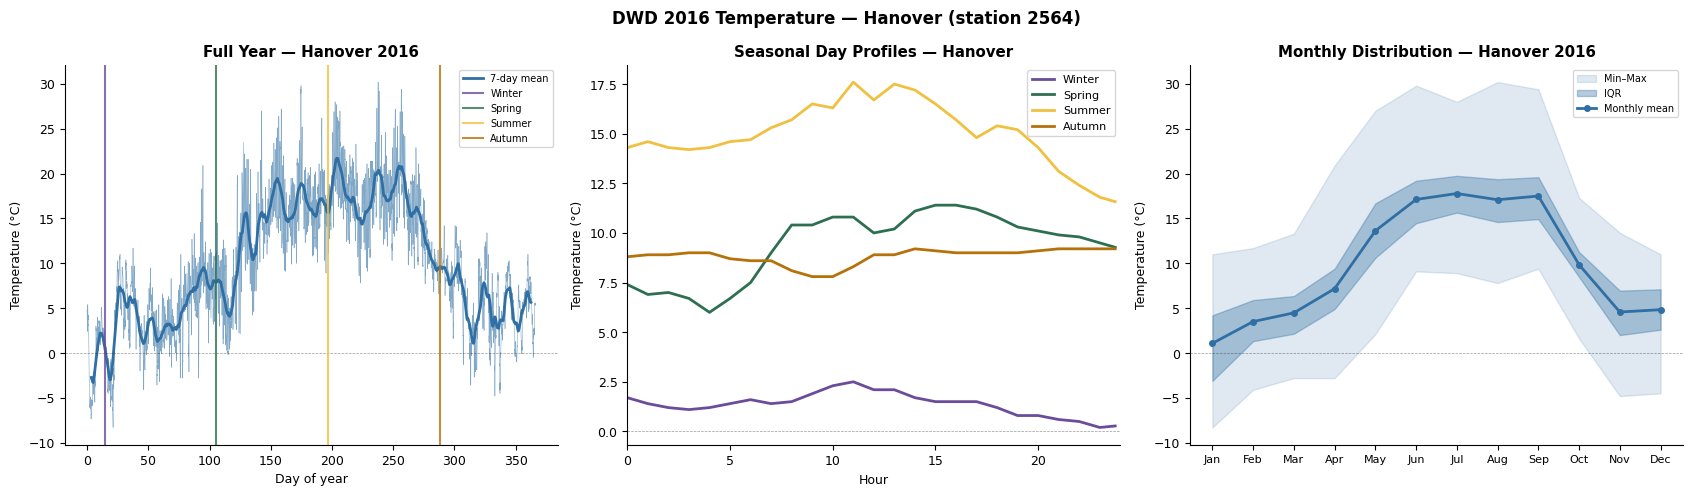

In [14]:
han = temp_han_15['temp_C'].values
t_year = np.arange(len(han)) / 96   # day of year
t_day  = np.arange(96) * 0.25

SEASON_COLORS = {'Winter':'#6B4C9A','Spring':'#2E6F52',
                 'Summer':'#F0C040','Autumn':'#B5720A'}
seasons = {
    'Winter': slice(14*96,  15*96),
    'Spring': slice((31+29+31+14)*96,         (31+29+31+15)*96),
    'Summer': slice((31+29+31+30+31+30+14)*96, (31+29+31+30+31+30+15)*96),
    'Autumn': slice((31+29+31+30+31+30+31+31+30+14)*96,
                     (31+29+31+30+31+30+31+31+30+15)*96),
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
plt.rcParams.update({'font.size':9,'axes.spines.top':False,
                     'axes.spines.right':False})

# Full year
ax = axes[0]
ax.plot(t_year, han, color='#2F6FA3', lw=0.4, alpha=0.6)
ax.plot(t_year, pd.Series(han).rolling(7*96,center=True).mean(),
        color='#2F6FA3', lw=2.0, label='7-day mean')
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
for name, slc in seasons.items():
    mid = (slc.start + slc.stop) / 2 / 96
    ax.axvline(mid, color=SEASON_COLORS[name], lw=1.5, alpha=0.8,
               label=name)
ax.set_title('Full Year — Hanover 2016', fontweight='bold')
ax.set_xlabel('Day of year'); ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=7)

# Seasonal days
ax = axes[1]
for name, slc in seasons.items():
    ax.plot(t_day, han[slc], color=SEASON_COLORS[name], lw=2.0, label=name)
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_title('Seasonal Day Profiles — Hanover', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=8); ax.set_xlim(0,24)

# Monthly distribution
ax = axes[2]
months = ['Jan','Feb','Mar','Apr','May','Jun',
          'Jul','Aug','Sep','Oct','Nov','Dec']
days_in = [31,29,31,30,31,30,31,31,30,31,30,31]
means,mins,maxs,p25s,p75s = [],[],[],[],[]
idx = 0
for d in days_in:
    chunk = han[idx:idx+d*96]
    means.append(np.mean(chunk)); mins.append(np.min(chunk))
    maxs.append(np.max(chunk));   p25s.append(np.percentile(chunk,25))
    p75s.append(np.percentile(chunk,75)); idx += d*96
x = np.arange(12)
ax.fill_between(x, mins, maxs,  alpha=0.15, color='#2F6FA3', label='Min–Max')
ax.fill_between(x, p25s, p75s,  alpha=0.35, color='#2F6FA3', label='IQR')
ax.plot(x, means, color='#2F6FA3', lw=2.0, marker='o', markersize=4,
        label='Monthly mean')
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_xticks(x, months, fontsize=8)
ax.set_title('Monthly Distribution — Hanover 2016', fontweight='bold')
ax.set_ylabel('Temperature (°C)'); ax.legend(fontsize=7)

fig.suptitle('DWD 2016 Temperature — Hanover (station 2564)',
             fontweight='bold', fontsize=12)
plt.tight_layout(); plt.show()

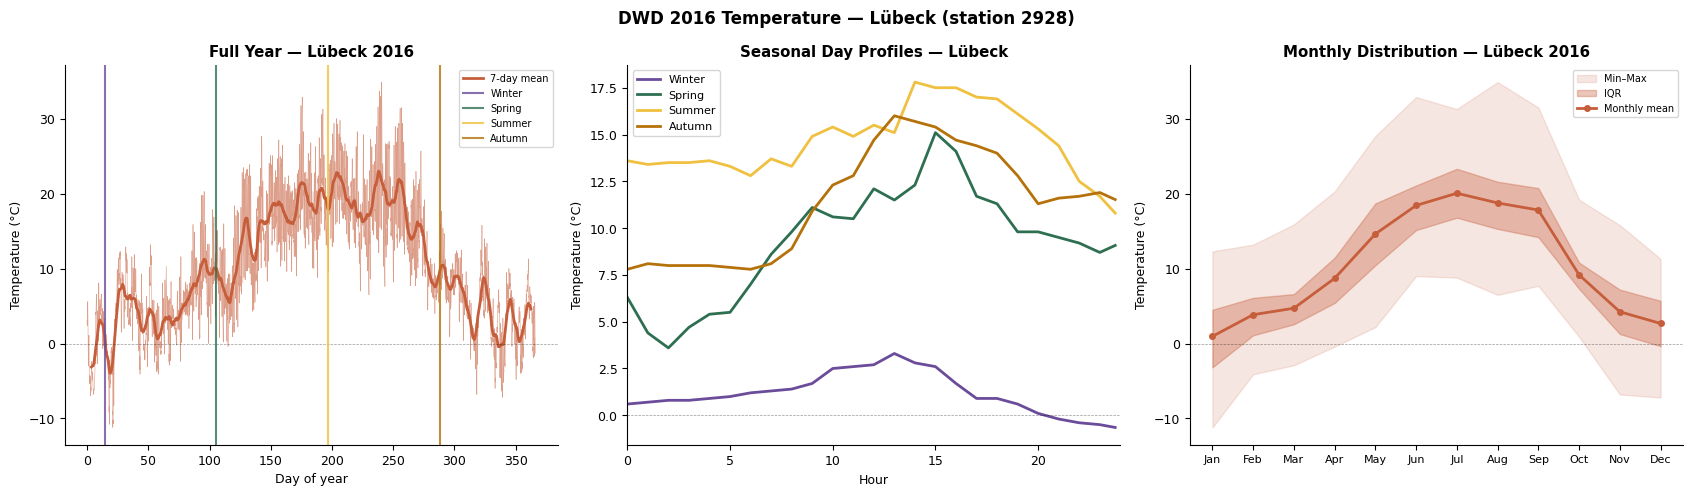

In [15]:
lub = temp_lub_15['temp_C'].values
t_year_lub = np.arange(len(lub)) / 96

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Full year
ax = axes[0]
ax.plot(t_year_lub, lub, color='#C65D3B', lw=0.4, alpha=0.6)
ax.plot(t_year_lub, pd.Series(lub).rolling(7*96,center=True).mean(),
        color='#C65D3B', lw=2.0, label='7-day mean')
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
for name, slc in seasons.items():
    mid = (slc.start + slc.stop) / 2 / 96
    ax.axvline(mid, color=SEASON_COLORS[name], lw=1.5, alpha=0.8, label=name)
ax.set_title('Full Year — Lübeck 2016', fontweight='bold')
ax.set_xlabel('Day of year'); ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=7)

# Seasonal days
ax = axes[1]
for name, slc in seasons.items():
    ax.plot(t_day, lub[slc], color=SEASON_COLORS[name], lw=2.0, label=name)
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_title('Seasonal Day Profiles — Lübeck', fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=8); ax.set_xlim(0,24)

# Monthly distribution
ax = axes[2]
means,mins,maxs,p25s,p75s = [],[],[],[],[]
idx = 0
for d in days_in:
    chunk = lub[idx:idx+d*96]
    means.append(np.mean(chunk)); mins.append(np.min(chunk))
    maxs.append(np.max(chunk));   p25s.append(np.percentile(chunk,25))
    p75s.append(np.percentile(chunk,75)); idx += d*96
ax.fill_between(x, mins, maxs,  alpha=0.15, color='#C65D3B', label='Min–Max')
ax.fill_between(x, p25s, p75s,  alpha=0.35, color='#C65D3B', label='IQR')
ax.plot(x, means, color='#C65D3B', lw=2.0, marker='o', markersize=4,
        label='Monthly mean')
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_xticks(x, months, fontsize=8)
ax.set_title('Monthly Distribution — Lübeck 2016', fontweight='bold')
ax.set_ylabel('Temperature (°C)'); ax.legend(fontsize=7)

fig.suptitle('DWD 2016 Temperature — Lübeck (station 2928)',
             fontweight='bold', fontsize=12)
plt.tight_layout(); plt.show()

Temperature statistics 2016:
                          Hanover       Lübeck
Annual mean                  9.90        10.35 °C
Winter mean                  1.38         1.23 °C
Summer mean                 15.08        14.67 °C
Annual min                  -8.30       -11.20 °C
Annual max                  30.20        34.90 °C


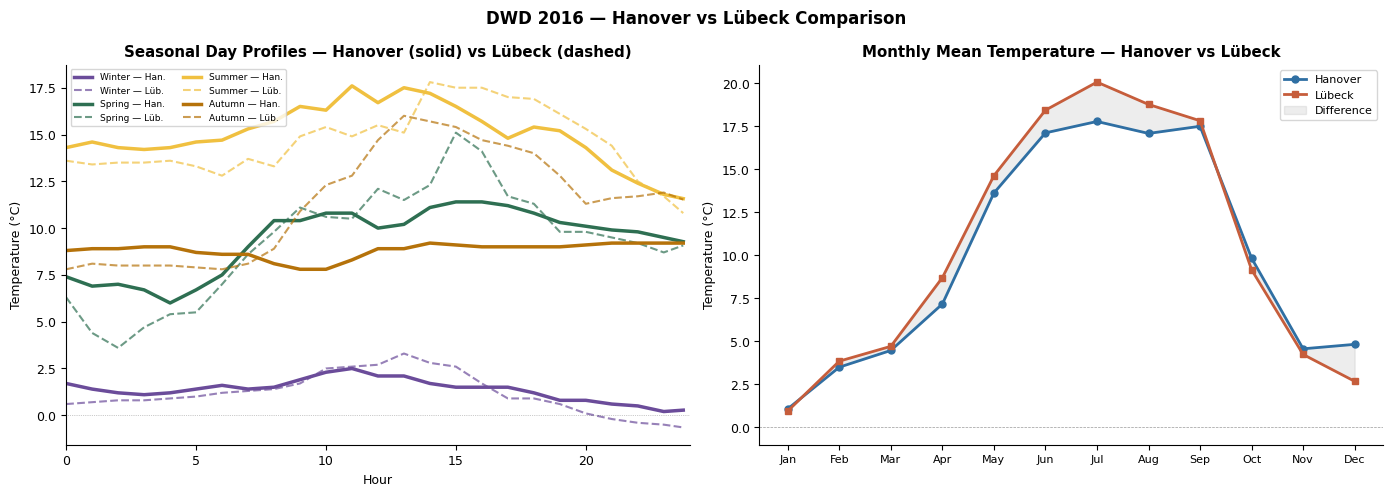

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Seasonal day overlay
ax = axes[0]
for name, slc in seasons.items():
    ax.plot(t_day, han[slc], color=SEASON_COLORS[name], lw=2.5,
            ls='-',  label=f'{name} — Han.')
    ax.plot(t_day, lub[slc], color=SEASON_COLORS[name], lw=1.5,
            ls='--', alpha=0.7, label=f'{name} — Lüb.')
ax.axhline(0, color='k', lw=0.5, ls=':', alpha=0.4)
ax.set_title('Seasonal Day Profiles — Hanover (solid) vs Lübeck (dashed)',
             fontweight='bold')
ax.set_xlabel('Hour'); ax.set_ylabel('Temperature (°C)')
ax.legend(fontsize=6.5, ncol=2); ax.set_xlim(0,24)

# Monthly mean comparison
ax = axes[1]
han_means, lub_means = [], []
idx = 0
for d in days_in:
    han_means.append(np.mean(han[idx:idx+d*96]))
    lub_means.append(np.mean(lub[idx:idx+d*96]))
    idx += d*96
ax.plot(x, han_means, color='#2F6FA3', lw=2.0, marker='o',
        markersize=5, label='Hanover')
ax.plot(x, lub_means, color='#C65D3B', lw=2.0, marker='s',
        markersize=5, label='Lübeck')
ax.fill_between(x, han_means, lub_means, alpha=0.15, color='#888888',
                label='Difference')
ax.axhline(0, color='k', lw=0.5, ls='--', alpha=0.4)
ax.set_xticks(x, months, fontsize=8)
ax.set_title('Monthly Mean Temperature — Hanover vs Lübeck',
             fontweight='bold')
ax.set_ylabel('Temperature (°C)'); ax.legend(fontsize=8)

# Print stats
print("Temperature statistics 2016:")
print(f"{'':20s} {'Hanover':>12s} {'Lübeck':>12s}")
print(f"{'Annual mean':20s} {np.mean(han):>12.2f} {np.mean(lub):>12.2f} °C")
print(f"{'Winter mean':20s} {np.mean(han[seasons['Winter']]):>12.2f} "
      f"{np.mean(lub[seasons['Winter']]):>12.2f} °C")
print(f"{'Summer mean':20s} {np.mean(han[seasons['Summer']]):>12.2f} "
      f"{np.mean(lub[seasons['Summer']]):>12.2f} °C")
print(f"{'Annual min':20s} {np.min(han):>12.2f} {np.min(lub):>12.2f} °C")
print(f"{'Annual max':20s} {np.max(han):>12.2f} {np.max(lub):>12.2f} °C")

fig.suptitle('DWD 2016 — Hanover vs Lübeck Comparison',
             fontweight='bold', fontsize=12)
plt.tight_layout(); plt.show()

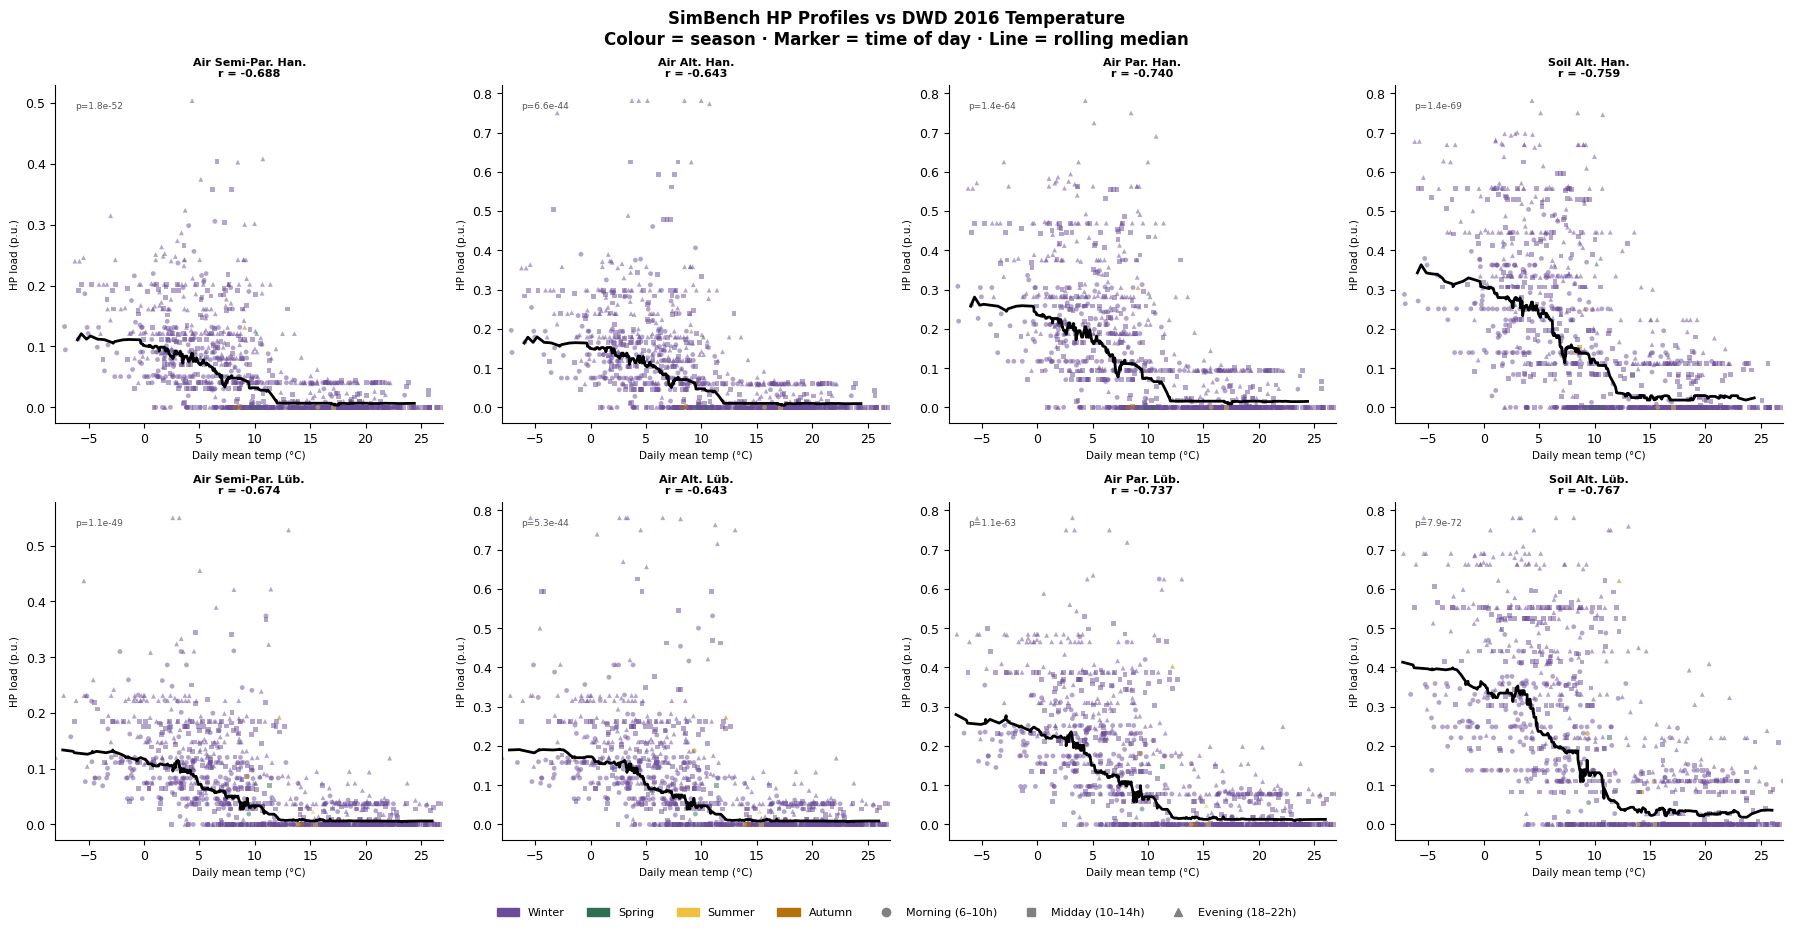

In [19]:
from scipy.stats import pearsonr
from scipy.ndimage import uniform_filter1d
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

n = min(len(han), len(lub), len(lp))

hp_profiles = {
    'Air Semi-Par. Han.': ('Air_Semi-Parallel_1_pload', han[:n], '#2F6FA3'),
    'Air Alt. Han.':      ('Air_Alternative_1_pload',   han[:n], '#2F6FA3'),
    'Air Par. Han.':      ('Air_Parallel_1_pload',      han[:n], '#2F6FA3'),
    'Soil Alt. Han.':     ('Soil_Alternative_1_pload',  han[:n], '#2F6FA3'),
    'Air Semi-Par. Lüb.': ('Air_Semi-Parallel_2_pload', lub[:n], '#C65D3B'),
    'Air Alt. Lüb.':      ('Air_Alternative_2_pload',   lub[:n], '#C65D3B'),
    'Air Par. Lüb.':      ('Air_Parallel_2_pload',      lub[:n], '#C65D3B'),
    'Soil Alt. Lüb.':     ('Soil_Alternative_2_pload',  lub[:n], '#C65D3B'),
}

# Season label per 15-min step
season_per_step = np.zeros(n, dtype=int)
season_per_step[seasons['Spring'].start:seasons['Spring'].stop] = 1
season_per_step[seasons['Summer'].start:seasons['Summer'].stop] = 2
season_per_step[seasons['Autumn'].start:seasons['Autumn'].stop] = 3

SCOL = {0:'#6B4C9A', 1:'#2E6F52', 2:'#F0C040', 3:'#B5720A'}
SLAB = {0:'Winter', 1:'Spring', 2:'Summer', 3:'Autumn'}

for ax, (label, (col, temp, base_color)) in zip(axes, hp_profiles.items()):
    hp_vals = lp[col].values[:n]

    # Hourly means (96 values per day → 1 per hour across 366 days)
    # Group by hour of day to show intraday pattern
    n_days = n // 96
    temp_2d = temp[:n_days*96].reshape(n_days, 96)
    hp_2d   = hp_vals[:n_days*96].reshape(n_days, 96)
    seas_2d = season_per_step[:n_days*96].reshape(n_days, 96)

    # Plot scatter colored by season, using daily means per time block
    # Morning (6–10h), Midday (10–14h), Evening (18–22h)
    blocks = {'Morning\n(6–10h)': slice(24,40),
              'Midday\n(10–14h)': slice(40,56),
              'Evening\n(18–22h)': slice(72,88)}
    markers = {'Morning\n(6–10h)': 'o',
               'Midday\n(10–14h)': 's',
               'Evening\n(18–22h)': '^'}

    for s_idx in range(4):
        mask = seas_2d[:, 0] == s_idx
        for block_label, blk in blocks.items():
            t_block  = temp_2d[mask, blk].mean(axis=1)
            hp_block = hp_2d[mask,  blk].mean(axis=1)
            ax.scatter(t_block, hp_block,
                       color=SCOL[s_idx], alpha=0.5, s=12,
                       marker=markers[block_label],
                       edgecolors='none')

    # Nonlinear fit: piecewise — HP on below T_cutoff, off above
    # Estimate cutoff as temperature where HP drops to ~5% of max
    all_temp = temp[:n_days*96].reshape(n_days, 96).mean(axis=1)
    all_hp   = hp_vals[:n_days*96].reshape(n_days, 96).mean(axis=1)

    # Bin by temperature and take median — shows true nonlinear shape
    t_sorted_idx = np.argsort(all_temp)
    t_sorted = all_temp[t_sorted_idx]
    h_sorted = all_hp[t_sorted_idx]
    # Rolling median over 30-day window
    h_smooth = pd.Series(h_sorted).rolling(30, center=True, min_periods=5).median()
    ax.plot(t_sorted, h_smooth, color='k', lw=2.0, ls='-', label='Rolling median')

    r, p = pearsonr(all_temp, all_hp)
    ax.set_title(f'{label}\nr = {r:.3f}', fontweight='bold', fontsize=8)
    ax.set_xlabel('Daily mean temp (°C)', fontsize=7.5)
    ax.set_ylabel('HP load (p.u.)', fontsize=7.5)
    ax.set_xlim(-8, 27)
    ax.text(0.05, 0.93, f'p={p:.1e}', transform=ax.transAxes,
            fontsize=6.5, color='#555555')

# Shared legends
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
season_handles = [Patch(color=SCOL[s], label=SLAB[s]) for s in range(4)]
time_handles   = [Line2D([0],[0], marker=m, color='grey', ls='none',
                          markersize=6, label=b.replace('\n',' '))
                  for b, m in markers.items()]
fig.legend(handles=season_handles + time_handles,
           loc='lower center', ncol=7, fontsize=8,
           bbox_to_anchor=(0.5, -0.04), frameon=False)

fig.suptitle('SimBench HP Profiles vs DWD 2016 Temperature\n'
             'Colour = season · Marker = time of day · Line = rolling median',
             fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()